# Tugas Besar ML — Part 2
## Prediksi Curah Hujan Harian di Stasiun Kemayoran (Jakarta Pusat)

**Alur CRISP-DM yang dikerjakan pada notebook ini**

1. **Data Understanding** — profil data, missing value, sentinel BMKG, distribusi target.
2. **Data Preparation** — pembersihan, pemilihan stasiun, imputasi, feature engineering, split.
3. **Modeling** — Logistic Regression (baseline) dan Random Forest, masing-masing di-tuning dengan `GridSearchCV`.
4. **Evaluation** — accuracy, precision, recall, F1, ROC-AUC, confusion matrix, kurva ROC/PR.
5. **Analysis (goodfit)** — membandingkan performa train vs test, cross-validation, dan learning curve untuk menentukan model yang **goodfit** (tidak overfit / underfit).
6. **Deployment artifact** — menyimpan `model.pkl`, `features.pkl`, dan `metadata.json` (termasuk threshold) untuk API/web app.

**Definisi target:** `1 = hujan lebat/sedang (RR ≥ 20 mm/hari)`, `0 = lainnya`.

> Notebook ini dapat dijalankan lokal (`../data`) maupun di Google Colab (data diunduh otomatis dari Kaggle).

## 0. Import library & konfigurasi

In [1]:
import json
import os
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import Markdown, display
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             average_precision_score, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate,
                                     learning_curve, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

RANDOM_STATE = 42
STATION_ID = 96745                 # Stasiun Meteorologi Kemayoran, Jakarta Pusat
TARGET_MM = 20                     # ambang hujan lebat/sedang (mm/hari)
FEATURES = ["Tn", "Tx", "Tavg", "RH_avg", "ss", "ff_x", "ff_avg",
            "rain_yesterday", "month"]
SENTINELS = [8888, 9999]

FIG_DIR = Path("../docs/assets")
try:
    FIG_DIR.mkdir(parents=True, exist_ok=True)
except OSError:
    FIG_DIR = Path("assets")
    FIG_DIR.mkdir(exist_ok=True)

print("Konfigurasi siap. Figure disimpan ke:", FIG_DIR.resolve())

Konfigurasi siap. Figure disimpan ke: /Users/regi.suyono/kuliah/machine-learning/tugas-besar/docs/assets


## 1. Load dataset

Tiga file yang dipakai: `climate_data.csv`, `station_detail.csv`, dan `province_detail.csv`.
Jika notebook dijalankan lokal dari folder `notebooks/`, data dibaca dari `../data`.
Jika dijalankan di Colab, data diambil otomatis tanpa upload manual: notebook memakai CSV yang sudah ada di runtime, atau mengunduh dataset publik Kaggle (`greegtitan/indonesia-climate`).

In [2]:
DATA_DIR = Path("../data")
if not (DATA_DIR / "climate_data.csv").exists():
    # Google Colab: pakai CSV yang sudah ada di runtime, atau unduh otomatis dari Kaggle.
    for candidate in (Path("/content/data"), Path("/content")):
        if (candidate / "climate_data.csv").exists():
            DATA_DIR = candidate
            break
    else:
        try:
            import kagglehub  # type: ignore
        except ImportError:
            import subprocess
            import sys
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
                           check=True)
            import kagglehub  # type: ignore
        DATA_DIR = Path(kagglehub.dataset_download("greegtitan/indonesia-climate"))
        print(f"Dataset diunduh otomatis dari Kaggle: {DATA_DIR}")

raw = pd.read_csv(DATA_DIR / "climate_data.csv")
station_detail = pd.read_csv(DATA_DIR / "station_detail.csv")
province_detail = pd.read_csv(DATA_DIR / "province_detail.csv")

station_info = station_detail.merge(province_detail, on="province_id", how="left")
selected = station_info[station_info["station_id"] == STATION_ID].iloc[0]

print(f"File data      : {DATA_DIR / 'climate_data.csv'}")
print(f"Ukuran dataset : {raw.shape[0]:,} baris x {raw.shape[1]} kolom")
print(f"Jumlah stasiun : {raw['station_id'].nunique()}")
print(f"Stasiun dipilih: {STATION_ID} — {selected['station_name']}, {selected['region_name']}")
print(f"Provinsi       : {selected['province_name']}")

File data      : ../data/climate_data.csv
Ukuran dataset : 589,265 baris x 12 kolom
Jumlah stasiun : 173
Stasiun dipilih: 96745 — Stasiun Meteorologi Kemayoran, Kota Adm. Jakarta Pusat
Provinsi       : DKI Jakarta


## 2. Data Understanding (EDA)

Pemeriksaan yang dilakukan:
- tipe data dan statistik deskriptif,
- jumlah missing value dan nilai sentinel BMKG (`8888`, `9999`),
- distribusi kelas target (cek ketidakseimbangan),
- korelasi antar variabel cuaca,
- distribusi curah hujan `RR`.

In [3]:
print("Tipe data:")
print(raw.dtypes.to_string())
print("\nStatistik deskriptif (stasiun terpilih):")
display(raw[raw["station_id"] == STATION_ID].describe().T.round(3))

sentinel_counts = {s: int((raw.select_dtypes(include=np.number) == s).sum().sum())
                   for s in SENTINELS}
print("\nJumlah nilai sentinel pada seluruh dataset:", sentinel_counts)
print("Catatan: sentinel tetap diganti NaN agar aman apabila data diperbarui.")

Tipe data:
date           object
Tn            float64
Tx            float64
Tavg          float64
RH_avg        float64
RR            float64
ss            float64
ff_x          float64
ddd_x         float64
ff_avg        float64
ddd_car        object
station_id      int64

Statistik deskriptif (stasiun terpilih):


,count,mean,std,min,25%,50%,75%,max
Tn,3948.0,25.570,1.341,0.0,25.0,26.00,26.0,28.0
Tx,3977.0,32.406,1.571,23.8,31.6,32.60,33.4,37.0
Tavg,3992.0,28.503,1.033,24.1,27.9,28.60,29.2,34.3
RH_avg,3992.0,75.868,6.190,52.0,72.0,76.00,80.0,96.0
RR,3662.0,6.360,17.009,0.0,0.0,0.00,4.5,277.5
ss,3880.0,4.401,2.631,0.0,2.2,4.65,6.5,11.0
ff_x,4004.0,4.238,1.277,0.0,3.0,4.00,5.0,16.0
ddd_x,4004.0,221.093,109.078,0.0,100.0,270.00,310.0,360.0
ff_avg,4003.0,1.860,0.870,0.0,1.0,2.00,2.0,5.0
station_id,4004.0,96745.000,0.000,96745.0,96745.0,96745.00,96745.0,96745.0



Jumlah nilai sentinel pada seluruh dataset: {8888: 0, 9999: 0}
Catatan: sentinel tetap diganti NaN agar aman apabila data diperbarui.


In [4]:
station_raw = raw[raw["station_id"] == STATION_ID].copy()
station_raw["date"] = pd.to_datetime(station_raw["date"], format="%d-%m-%Y")
station_raw = station_raw.sort_values("date").reset_index(drop=True)
station_raw["target"] = (station_raw["RR"] >= TARGET_MM).astype("Int64")

print(f"Rentang tanggal stasiun: {station_raw['date'].min():%d %b %Y} – {station_raw['date'].max():%d %b %Y}")
print(f"Jumlah baris stasiun   : {len(station_raw):,}")
print(f"Duplikasi tanggal      : {station_raw['date'].duplicated().sum()}")
print("\nMissing value per kolom (sebelum pembersihan):")
print(station_raw.isna().sum().to_string())

Rentang tanggal stasiun: 01 Jan 2010 – 31 Dec 2020
Jumlah baris stasiun   : 4,004
Duplikasi tanggal      : 0

Missing value per kolom (sebelum pembersihan):
date            0
Tn             56
Tx             27
Tavg           12
RH_avg         12
RR            342
ss            124
ff_x            0
ddd_x           0
ff_avg          1
ddd_car         1
station_id      0
target          0


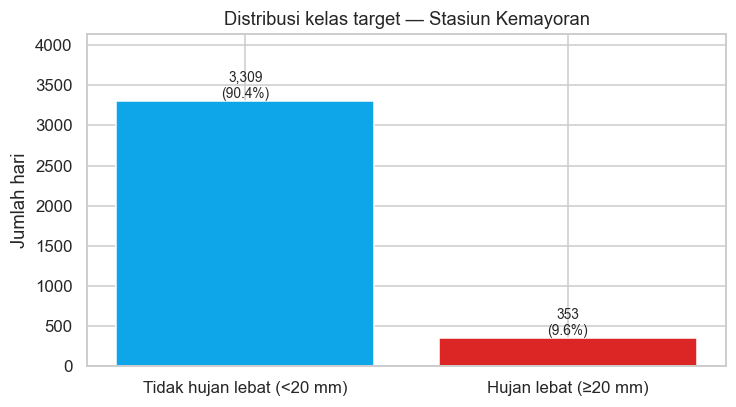

Baris dengan RR terukur: 3,662 hari (dipakai untuk model)
Rasio kelas: 1 positif untuk setiap 9.4 hari negatif
→ Data tidak seimbang; model akan memakai class_weight='balanced'.


In [5]:
counts = station_raw.loc[station_raw["RR"].notna(), "target"].value_counts().sort_index()
labels = ["Tidak hujan lebat (<20 mm)", "Hujan lebat (≥20 mm)"]
colors = ["#0EA5E9", "#DC2626"]
total = int(counts.sum())

fig, ax = plt.subplots(figsize=(6.8, 3.8))
bars = ax.bar(labels, counts.values, color=colors)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,}\n({v/total:.1%})",
            ha="center", va="bottom", fontsize=9)
ax.set_title("Distribusi kelas target — Stasiun Kemayoran")
ax.set_ylabel("Jumlah hari")
ax.set_ylim(0, counts.max() * 1.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "class_dist.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Baris dengan RR terukur: {total:,} hari (dipakai untuk model)")

print(f"Rasio kelas: 1 positif untuk setiap {counts[0]/max(counts[1],1):.1f} hari negatif")
print("→ Data tidak seimbang; model akan memakai class_weight='balanced'.")

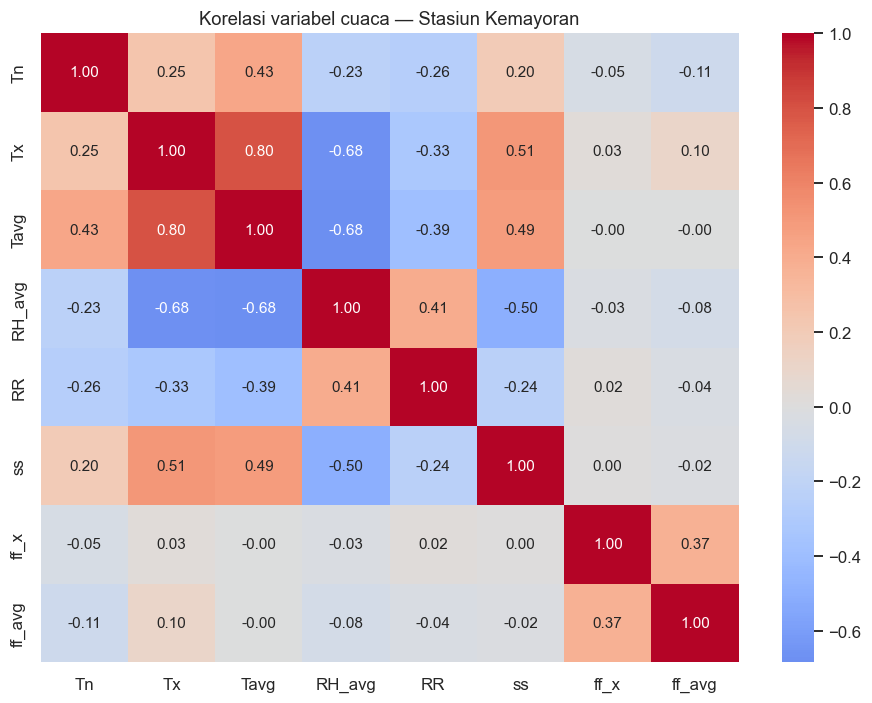

Korelasi terhadap RR (curah hujan hari ini):
RH_avg    0.405
ff_x      0.023
ff_avg   -0.037
ss       -0.236
Tn       -0.259
Tx       -0.328
Tavg     -0.389


In [6]:
num_cols = ["Tn", "Tx", "Tavg", "RH_avg", "RR", "ss", "ff_x", "ff_avg"]
fig, ax = plt.subplots(figsize=(8.5, 6.5))
corr = station_raw[num_cols].corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korelasi variabel cuaca — Stasiun Kemayoran")
fig.tight_layout()
fig.savefig(FIG_DIR / "correlation.png", dpi=200, bbox_inches="tight")
plt.show()

print("Korelasi terhadap RR (curah hujan hari ini):")
print(corr["RR"].drop("RR").sort_values(ascending=False).round(3).to_string())

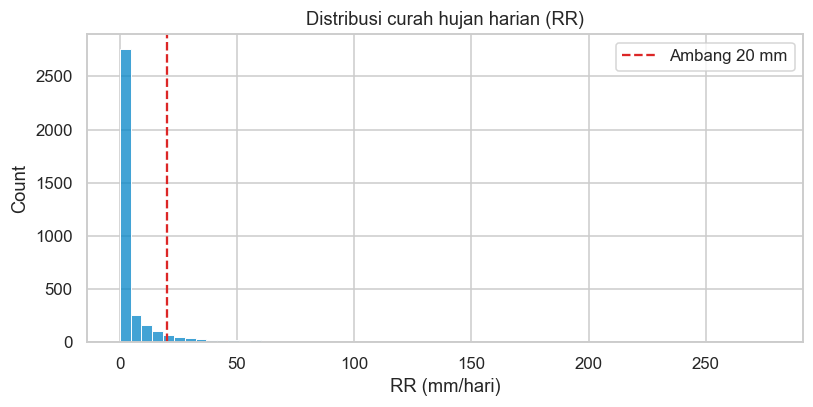

count    3662.00
mean        6.36
std        17.01
min         0.00
25%         0.00
50%         0.00
75%         4.50
max       277.50


In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
sns.histplot(station_raw["RR"].dropna(), bins=60, ax=ax, color="#0284C7")
ax.axvline(TARGET_MM, color="#DC2626", ls="--", label=f"Ambang {TARGET_MM} mm")
ax.set_title("Distribusi curah hujan harian (RR)")
ax.set_xlabel("RR (mm/hari)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "rain_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print(station_raw["RR"].describe().round(2).to_string())

## 3. Data Preparation

Langkah yang dilakukan:

1. **Sentinel → NaN.** Nilai `8888` (tidak terukur) dan `9999` (tidak ada pengukuran) diganti `NaN`.
2. **Filter satu stasiun** (Kemayoran) agar pola musiman konsisten.
3. **Rapikan deret waktu.** Data di-*reindex* per hari kalender agar `rain_yesterday` benar-benar lag-1 hari, bukan lag-1 baris.
4. **Feature engineering:**
   - `rain_yesterday` = curah hujan hari sebelumnya (lag-1),
   - `month` = bulan (menangkap musim hujan/kemarau).
5. **Target:** `1` jika `RR ≥ 20 mm`, `0` jika tidak. Baris dengan `RR` hilang **tidak diimputasi** karena akan mengarang label.
6. **Pemeriksaan kewajaran:** nilai `Tn = 0 °C` (tidak fisis untuk Jakarta) diperlakukan sebagai missing, lalu diimputasi median di dalam pipeline.
7. **Imputasi fitur** dilakukan di dalam `Pipeline` dengan median **hanya dari data train** → mencegah data leakage. Fitur yang hilang: `Tn`, `Tx`, `Tavg`, `RH_avg`, `ss`, `ff_avg`, `rain_yesterday`.
8. **Split:** 80% train / 20% test, stratified, `random_state=42`.
9. **Scaling:** `StandardScaler` hanya untuk Logistic Regression (di dalam pipeline); Random Forest tidak memerlukan scaling.

In [8]:
# 1) Sentinel -> NaN
df = raw.replace(SENTINELS, np.nan)

# 2) Satu stasiun
d = df[df["station_id"] == STATION_ID].copy()
d["date"] = pd.to_datetime(d["date"], format="%d-%m-%Y")
d = d.sort_values("date").set_index("date").asfreq("D").reset_index()

# 3) Feature engineering (hanya memakai informasi masa lalu)
d["rain_yesterday"] = d["RR"].shift(1).ffill()   # lag-1 hari; ffill memakai nilai terakhir yang teramati
d["month"] = d["date"].dt.month

# 3b) Pemeriksaan kewajaran nilai
# Tn = 0 °C tidak fisis untuk Jakarta -> perlakukan sebagai tidak terukur.
cek = {
    "Tn == 0": int((d["Tn"] == 0).sum()),
    "Tn > Tx": int((d["Tn"] > d["Tx"]).sum()),
    "Tavg di luar [Tn, Tx]": int(((d["Tavg"] < d["Tn"]) | (d["Tavg"] > d["Tx"])).sum()),
}
print("Pemeriksaan kewajaran nilai:", cek)
d.loc[d["Tn"] == 0, "Tn"] = np.nan

# 4) Target; hari tanpa pengukuran RR dibuang, bukan diimputasi
d["target"] = np.where(d["RR"].isna(), np.nan, (d["RR"] >= TARGET_MM).astype(float))
model_df = d.dropna(subset=["target"]).reset_index(drop=True)
model_df["target"] = model_df["target"].astype(int)

print(f"Baris stasiun setelah reindex harian : {len(d):,}")
print(f"Baris dipakai untuk model            : {len(model_df):,}")
print(f"Baris dibuang karena RR tidak terukur: {len(d) - len(model_df):,}")
print(f"Rentang data model                   : {model_df['date'].min():%d %b %Y} – {model_df['date'].max():%d %b %Y}")
print(f"Proporsi positif                     : {model_df['target'].mean():.2%} ({model_df['target'].sum():,} hari)")
print("\nMissing value fitur (akan diimputasi median di dalam pipeline):")
print(model_df[FEATURES].isna().sum().to_string())

Pemeriksaan kewajaran nilai: {'Tn == 0': 5, 'Tn > Tx': 3, 'Tavg di luar [Tn, Tx]': 15}
Baris stasiun setelah reindex harian : 4,018
Baris dipakai untuk model            : 3,662
Baris dibuang karena RR tidak terukur: 356
Rentang data model                   : 01 Jan 2010 – 31 Dec 2020
Proporsi positif                     : 9.64% (353 hari)

Missing value fitur (akan diimputasi median di dalam pipeline):
Tn                 47
Tx                 24
Tavg               10
RH_avg             10
ss                118
ff_x                0
ff_avg              1
rain_yesterday      1
month               0


In [9]:
X = model_df[FEATURES]
y = model_df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]:,} baris | positif {y_train.sum():,} ({y_train.mean():.2%})")
print(f"Test : {X_test.shape[0]:,} baris | positif {y_test.sum():,} ({y_test.mean():.2%})")

Train: 2,929 baris | positif 282 (9.63%)
Test : 733 baris | positif 71 (9.69%)


## 4. Modeling & Tuning

Dua algoritma dari Part 1 di-tuning satu per satu:

| Model | Peran | Ruang tuning |
|---|---|---|
| Logistic Regression | baseline yang interpretatif | `C` (0.01–100), `penalty` L1/L2 |
| Random Forest | model non-linear utama | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features` |

Strategi:
- `GridSearchCV` dengan `StratifiedKFold(5)` dan `scoring="f1"` (cocok untuk kelas tidak seimbang).
- `class_weight="balanced"` pada kedua model.
- Untuk Random Forest, selain model **best-CV**, dipilih juga model **1-SE (one standard error)**: kandidat yang skornya masih dalam 1 standar deviasi dari model terbaik. Karena kompleksitas RF terutama dikendalikan `max_depth`, dipilih kedalaman minimum pada zona 1-SE, lalu CV F1 tertinggi pada kedalaman tersebut. Aturan ini dipakai untuk mencari model yang **goodfit**, bukan hanya skor CV tertinggi.
- Imputasi dan scaling berada di dalam pipeline agar tidak bocor dari test ke train.

In [10]:
def make_logreg(**params):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, class_weight="balanced",
                                     random_state=RANDOM_STATE, **params)),
    ])

def make_rf(**params):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(class_weight="balanced",
                                         random_state=RANDOM_STATE,
                                         n_jobs=-1, **params)),
    ])

def metric_dict(y_true, y_pred, y_proba):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_proba),
        "pr_auc": average_precision_score(y_true, y_proba),
    }

def evaluate(model, name, threshold=0.5, fit=True):
    if fit:
        model.fit(X_train, y_train)
    rows = []
    for split, X_, y_ in [("train", X_train, y_train), ("test", X_test, y_test)]:
        proba = model.predict_proba(X_)[:, 1]
        pred = (proba >= threshold).astype(int)
        row = {"model": name, "split": split, "threshold": threshold}
        row.update(metric_dict(y_, pred, proba))
        rows.append(row)
    return rows

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Helper siap.")

Helper siap.


In [11]:
# Baseline kedua algoritma (parameter default Part 1)
baseline_models = {
    "Logistic Regression (baseline)": make_logreg(),
    "Random Forest (baseline)": make_rf(n_estimators=100),
}

baseline_results = []
for name, mdl in baseline_models.items():
    baseline_results += evaluate(mdl, name, threshold=0.5)

pd.DataFrame(baseline_results).round(4)

,model,split,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression (baseline),train,0.5,0.7893,0.2877,0.8050,0.4239,0.8807,0.4363
1,Logistic Regression (baseline),test,0.5,0.7926,0.3005,0.8592,0.4453,0.9068,0.5719
2,Random Forest (baseline),train,0.5,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
3,Random Forest (baseline),test,0.5,0.9168,0.7273,0.2254,0.3441,0.8674,0.4536


In [12]:
# Tuning Logistic Regression
param_log = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l1", "l2"],
}
gs_log = GridSearchCV(make_logreg(solver="liblinear"), param_log,
                      scoring="f1", cv=cv, n_jobs=-1)
gs_log.fit(X_train, y_train)

print("Logistic Regression — parameter terbaik:")
print(gs_log.best_params_)
print(f"CV F1 terbaik: {gs_log.best_score_:.4f}")

log_cv = pd.DataFrame(gs_log.cv_results_)[
    ["param_model__C", "param_model__penalty", "mean_test_score", "std_test_score"]
].sort_values("mean_test_score", ascending=False)
log_cv.head(10).round(4)

Logistic Regression — parameter terbaik:
{'model__C': 10, 'model__penalty': 'l2'}
CV F1 terbaik: 0.4180


,param_model__C,param_model__penalty,mean_test_score,std_test_score
7,10.00,l2,0.4180,0.0303
8,100.00,l1,0.4180,0.0303
9,100.00,l2,0.4180,0.0303
6,10.00,l1,0.4176,0.0305
4,1.00,l1,0.4173,0.0320
5,1.00,l2,0.4151,0.0335
3,0.10,l2,0.4112,0.0292
2,0.10,l1,0.4104,0.0319
1,0.01,l2,0.3975,0.0377
0,0.01,l1,0.3793,0.0236


In [13]:
# Tuning Random Forest
param_rf = {
    "model__n_estimators": [200, 300],
    "model__max_depth": [4, 6, 8, 10, 12, None],
    "model__min_samples_leaf": [5, 10, 15, 20],
    "model__max_features": ["sqrt", 0.5, 0.7],
}
gs_rf = GridSearchCV(make_rf(), param_rf, scoring="f1", cv=cv, n_jobs=-1)
gs_rf.fit(X_train, y_train)

print("Random Forest — parameter terbaik (best CV):")
print(gs_rf.best_params_)
print(f"CV F1 terbaik: {gs_rf.best_score_:.4f}")

# Aturan 1-SE: ambil model paling sederhana yang masih dalam 1 standar deviasi
rf_cv = pd.DataFrame(gs_rf.cv_results_).copy()
batas_1se = gs_rf.best_score_ - rf_cv.loc[gs_rf.best_index_, "std_test_score"]
kandidat = rf_cv[rf_cv["mean_test_score"] >= batas_1se].copy()
kandidat["depth_sort"] = kandidat["param_model__max_depth"].apply(
    lambda v: 99 if v is None else v)

# Kompleksitas utama RF dikendalikan max_depth. Di antara kandidat 1-SE,
# ambil kedalaman minimum, lalu CV F1 tertinggi pada kedalaman tersebut.
min_depth = kandidat["depth_sort"].min()
kandidat = kandidat[kandidat["depth_sort"] == min_depth].sort_values(
    ["mean_test_score", "param_model__min_samples_leaf", "param_model__n_estimators"],
    ascending=[False, False, True])

rf_1se_params = {k.replace("model__", ""): v for k, v in kandidat.iloc[0]["params"].items()}
print(f"\nBatas 1-SE: {batas_1se:.4f} (best CV - 1 std)")
print(f"Kedalaman minimum dalam 1-SE: {min_depth if min_depth != 99 else None}")
print("Parameter model 1-SE terpilih:", rf_1se_params)

rf_cv.sort_values("mean_test_score", ascending=False).head(10)[
    ["params", "mean_test_score", "std_test_score"]
].round(4)

Random Forest — parameter terbaik (best CV):
{'model__max_depth': 10, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
CV F1 terbaik: 0.4612

Batas 1-SE: 0.4021 (best CV - 1 std)
Kedalaman minimum dalam 1-SE: 6
Parameter model 1-SE terpilih: {'max_depth': 6, 'max_features': 0.7, 'min_samples_leaf': 10, 'n_estimators': 300}


,params,mean_test_score,std_test_score
72,"{'model__max_depth': 10, 'model__max_features'...",0.4612,0.0592
91,"{'model__max_depth': 10, 'model__max_features'...",0.4573,0.0501
115,"{'model__max_depth': 12, 'model__max_features'...",0.4571,0.0528
98,"{'model__max_depth': 12, 'model__max_features'...",0.4551,0.0364
139,"{'model__max_depth': None, 'model__max_feature...",0.4547,0.0543
122,"{'model__max_depth': None, 'model__max_feature...",0.4547,0.0390
73,"{'model__max_depth': 10, 'model__max_features'...",0.4546,0.0539
90,"{'model__max_depth': 10, 'model__max_features'...",0.4537,0.0456
121,"{'model__max_depth': None, 'model__max_feature...",0.4536,0.0511
97,"{'model__max_depth': 12, 'model__max_features'...",0.4531,0.0427


In [14]:
# Model final kandidat
all_models = {
    "Logistic Regression (baseline)": make_logreg(),
    "Logistic Regression (tuned)": gs_log.best_estimator_,
    "Random Forest (baseline)": make_rf(n_estimators=100),
    "Random Forest (best CV)": gs_rf.best_estimator_,
    "Random Forest (tuned, 1-SE)": make_rf(**rf_1se_params),
}

results = []
for name, mdl in all_models.items():
    results += evaluate(mdl, name, threshold=0.5)

results_df = pd.DataFrame(results)
tabel_default = results_df.pivot_table(
    index="model", columns="split",
    values=["accuracy", "precision", "recall", "f1", "roc_auc"]
).round(4)
tabel_default

accuracy              f1         precision          recall         roc_auc        
split                              test   train    test   train      test   train    test   train    test   train
model                                                                                                            
Logistic Regression (baseline)   0.7926  0.7893  0.4453  0.4239    0.3005  0.2877  0.8592  0.8050  0.9068  0.8807
Logistic Regression (tuned)      0.7926  0.7897  0.4453  0.4243    0.3005  0.2881  0.8592  0.8050  0.9069  0.8806
Random Forest (baseline)         0.9168  1.0000  0.3441  1.0000    0.7273  1.0000  0.2254  1.0000  0.8674  1.0000
Random Forest (best CV)          0.8799  0.9259  0.5269  0.7095    0.4261  0.5699  0.6901  0.9397  0.8944  0.9808
Random Forest (tuned, 1-SE)      0.8076  0.8231  0.4471  0.4922    0.3098  0.3401  0.8028  0.8901  0.9002  0.9266

## 5. Threshold tuning (menyesuaikan target bisnis)

Target bisnis pada draft: **accuracy ≥ 0,80** dan **recall hujan lebat ≥ 0,70**.
Karena data tidak seimbang, threshold 0,5 belum tentu memenuhi target recall. Threshold dipilih dari **prediksi out-of-fold (OOF) pada data train** — bukan dari data test — dengan aturan:

> pilih threshold yang memaksimalkan F1 selama recall OOF ≥ 0,70.

Setelah threshold dipilih, baru dievaluasi pada data test. Ini menjaga data test tetap sebagai *hold-out* yang jujur.

In [15]:
def pilih_threshold(model, min_recall=0.70):
    oof = cross_val_predict(model, X_train, y_train, cv=cv,
                            method="predict_proba", n_jobs=-1)[:, 1]
    rows = []
    for th in np.arange(0.05, 0.96, 0.01):
        pred = (oof >= th).astype(int)
        rec = recall_score(y_train, pred, zero_division=0)
        if rec >= min_recall:
            rows.append({
                "threshold": round(float(th), 2),
                "precision": precision_score(y_train, pred, zero_division=0),
                "recall": rec,
                "f1": f1_score(y_train, pred, zero_division=0),
                "accuracy": accuracy_score(y_train, pred),
            })
    best = max(rows, key=lambda r: (r["f1"], r["precision"]))
    return best, pd.DataFrame(rows)

threshold_info = {}
for name in ["Logistic Regression (tuned)", "Random Forest (tuned, 1-SE)"]:
    info, curve = pilih_threshold(all_models[name])
    threshold_info[name] = info
    print(f"{name}: threshold={info['threshold']:.2f} | "
          f"OOF recall={info['recall']:.3f} | OOF F1={info['f1']:.3f}")

pd.DataFrame(threshold_info).T.round(4)

Logistic Regression (tuned): threshold=0.61 | OOF recall=0.709 | OOF F1=0.450


Random Forest (tuned, 1-SE): threshold=0.52 | OOF recall=0.720 | OOF F1=0.442


,threshold,precision,recall,f1,accuracy
Logistic Regression (tuned),0.61,0.3295,0.7092,0.4499,0.8330
"Random Forest (tuned, 1-SE)",0.52,0.3192,0.7199,0.4423,0.8252


In [16]:
# Evaluasi pada threshold hasil OOF
threshold_results = []
for name, info in threshold_info.items():
    threshold_results += evaluate(all_models[name], name,
                                  threshold=info["threshold"], fit=False)

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(4)

,model,split,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Logistic Regression (tuned),train,0.61,0.8354,0.3339,0.7128,0.4548,0.8806,0.4364
1,Logistic Regression (tuned),test,0.61,0.8431,0.3590,0.7887,0.4934,0.9069,0.5728
2,"Random Forest (tuned, 1-SE)",train,0.52,0.8378,0.3595,0.8759,0.5098,0.9266,0.5736
3,"Random Forest (tuned, 1-SE)",test,0.52,0.8213,0.3256,0.7887,0.4609,0.9002,0.4964


In [17]:
# Ringkasan operasional: baseline/best-CV pada 0.5, finalis pada threshold OOF
operational = results_df[results_df["split"] == "test"].copy().set_index("model")
for name, info in threshold_info.items():
    replacement = threshold_df[(threshold_df["model"] == name) &
                               (threshold_df["split"] == "test")].iloc[0]
    for col in ["threshold", "accuracy", "precision", "recall",
                "f1", "roc_auc", "pr_auc"]:
        operational.loc[name, col] = replacement[col]

operational = operational.reset_index()[[
    "model", "threshold", "accuracy", "precision",
    "recall", "f1", "roc_auc", "pr_auc"]]
operational.round(4).sort_values("f1", ascending=False)

,model,threshold,accuracy,precision,recall,f1,roc_auc,pr_auc
3,Random Forest (best CV),0.50,0.8799,0.4261,0.6901,0.5269,0.8944,0.4809
1,Logistic Regression (tuned),0.61,0.8431,0.3590,0.7887,0.4934,0.9069,0.5728
4,"Random Forest (tuned, 1-SE)",0.52,0.8213,0.3256,0.7887,0.4609,0.9002,0.4964
0,Logistic Regression (baseline),0.50,0.7926,0.3005,0.8592,0.4453,0.9068,0.5719
2,Random Forest (baseline),0.50,0.9168,0.7273,0.2254,0.3441,0.8674,0.4536


## 6. Evaluation

Bagian ini menyajikan:
- confusion matrix train & test untuk model kunci,
- kurva ROC dan Precision-Recall,
- feature importance / koefisien model,
- ringkasan cross-validation,
- learning curve untuk melihat bias/variance.

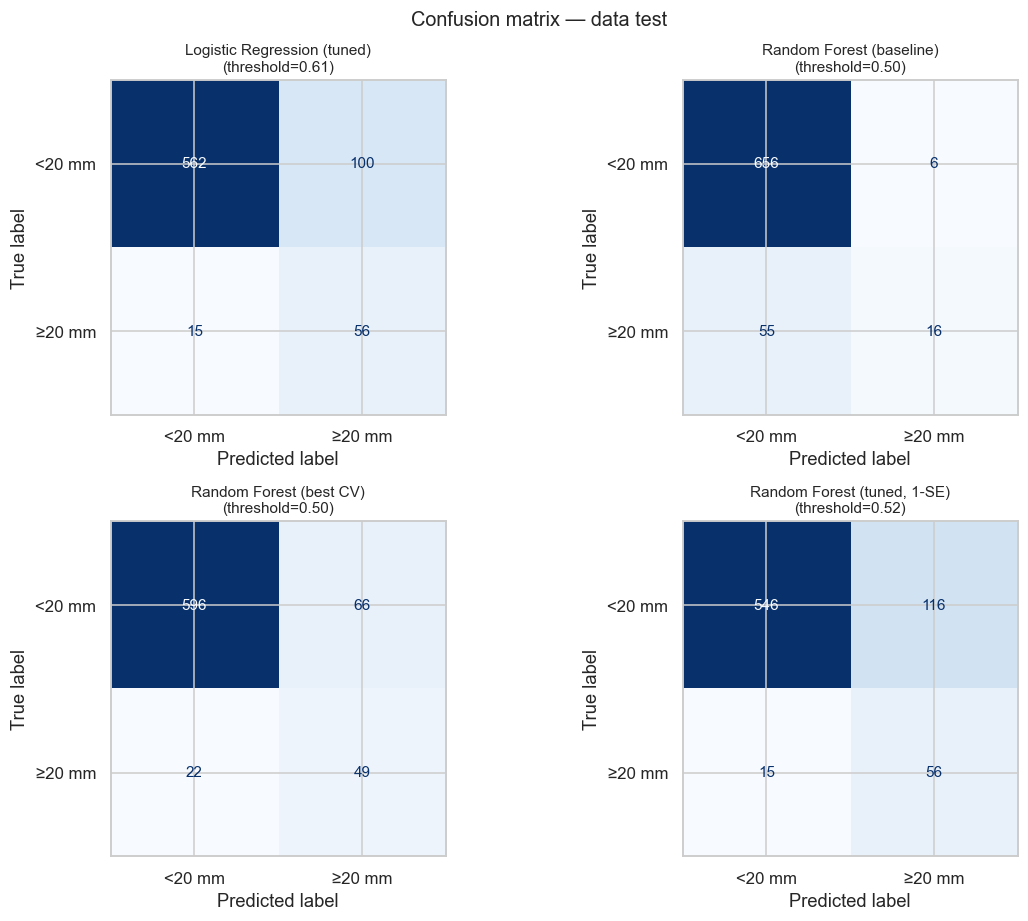

In [18]:
plot_models = [
    ("Logistic Regression (tuned)", threshold_info["Logistic Regression (tuned)"]["threshold"]),
    ("Random Forest (baseline)", 0.5),
    ("Random Forest (best CV)", 0.5),
    ("Random Forest (tuned, 1-SE)", threshold_info["Random Forest (tuned, 1-SE)"]["threshold"]),
]

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for ax, (name, th) in zip(axes.ravel(), plot_models):
    mdl = all_models[name]
    proba = mdl.predict_proba(X_test)[:, 1]
    pred = (proba >= th).astype(int)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["<20 mm", "≥20 mm"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\n(threshold={th:.2f})", fontsize=10)
fig.suptitle("Confusion matrix — data test", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_test.png", dpi=200, bbox_inches="tight")
plt.show()

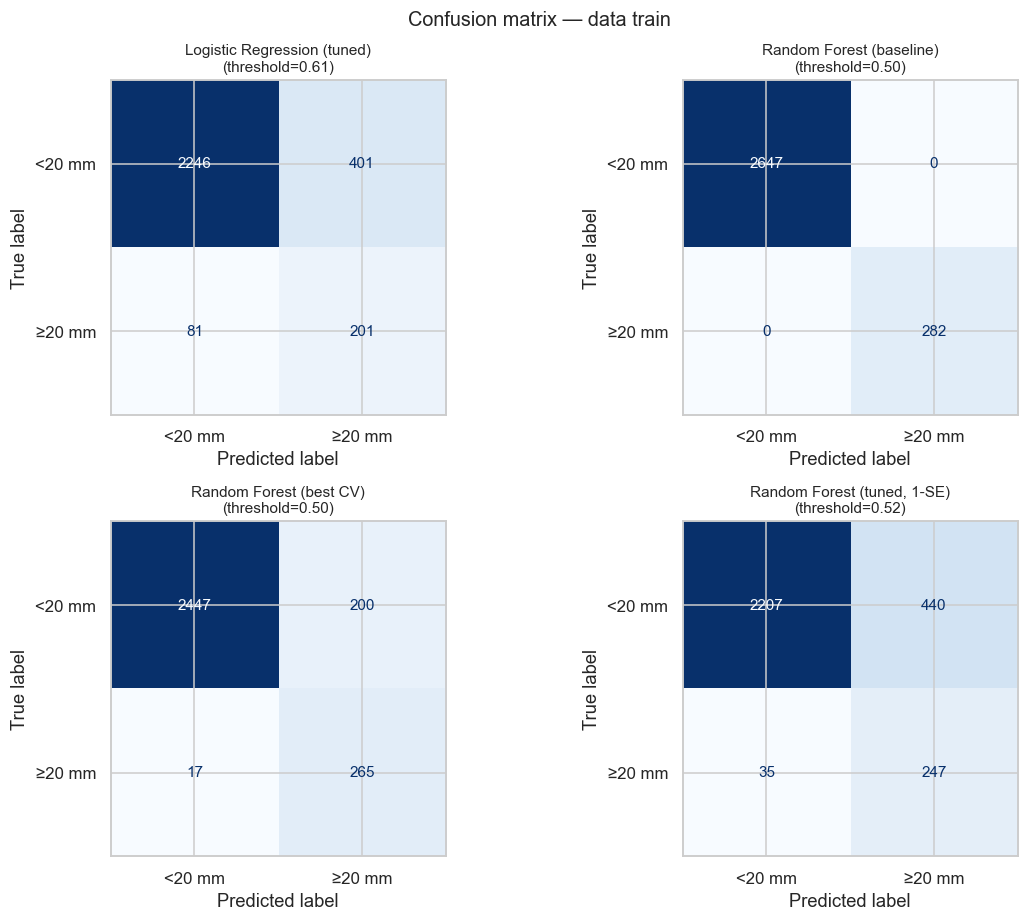

In [19]:
# Confusion matrix pada data train untuk melihat gejala overfit
fig, axes = plt.subplots(2, 2, figsize=(11, 8.5))
for ax, (name, th) in zip(axes.ravel(), plot_models):
    mdl = all_models[name]
    proba = mdl.predict_proba(X_train)[:, 1]
    pred = (proba >= th).astype(int)
    cm = confusion_matrix(y_train, pred)
    ConfusionMatrixDisplay(cm, display_labels=["<20 mm", "≥20 mm"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\n(threshold={th:.2f})", fontsize=10)
fig.suptitle("Confusion matrix — data train", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_train.png", dpi=200, bbox_inches="tight")
plt.show()

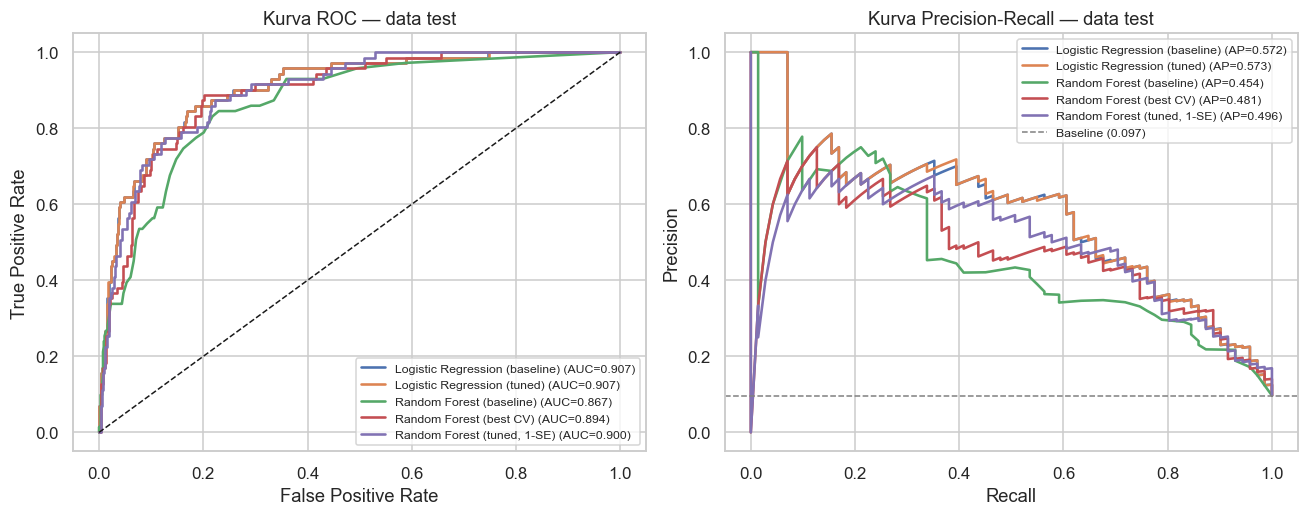

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

for name, mdl in all_models.items():
    proba = mdl.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=1.7,
                 label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, lw=1.7,
                 label=f"{name} (AP={average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("Kurva ROC — data test")
axes[0].legend(fontsize=8)

axes[1].axhline(y_test.mean(), color="grey", ls="--", lw=1,
                label=f"Baseline ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Kurva Precision-Recall — data test")
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIG_DIR / "roc_pr.png", dpi=200, bbox_inches="tight")
plt.show()

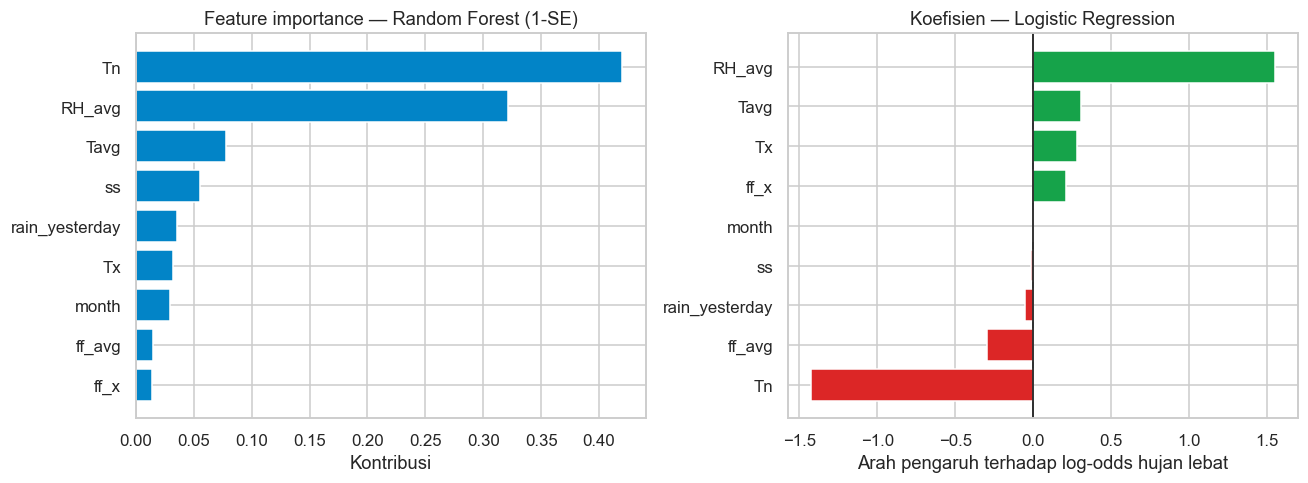

Feature importance RF:
       feature  importance
            Tn      0.4198
        RH_avg      0.3216
          Tavg      0.0774
            ss      0.0554
rain_yesterday      0.0353
            Tx      0.0322
         month      0.0295
        ff_avg      0.0146
          ff_x      0.0143


In [21]:
final_name = "Random Forest (tuned, 1-SE)"
final_model = all_models[final_name]
final_threshold = threshold_info[final_name]["threshold"]

# Feature importance Random Forest final
imp = pd.DataFrame({
    "feature": FEATURES,
    "importance": final_model.named_steps["model"].feature_importances_,
}).sort_values("importance", ascending=True)

# Koefisien Logistic Regression (fitur sudah distandardisasi)
coef_model = all_models["Logistic Regression (tuned)"]
coef = pd.DataFrame({
    "feature": FEATURES,
    "coefficient": coef_model.named_steps["model"].coef_[0],
}).sort_values("coefficient")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(imp["feature"], imp["importance"], color="#0284C7")
axes[0].set_title("Feature importance — Random Forest (1-SE)")
axes[0].set_xlabel("Kontribusi")

colors = ["#DC2626" if v < 0 else "#16A34A" for v in coef["coefficient"]]
axes[1].barh(coef["feature"], coef["coefficient"], color=colors)
axes[1].axvline(0, color="black", lw=1)
axes[1].set_title("Koefisien — Logistic Regression")
axes[1].set_xlabel("Arah pengaruh terhadap log-odds hujan lebat")

fig.tight_layout()
fig.savefig(FIG_DIR / "importance.png", dpi=200, bbox_inches="tight")
plt.show()

print("Feature importance RF:")
print(imp.sort_values("importance", ascending=False).round(4).to_string(index=False))

In [22]:
cv_rows = []
for name, mdl in all_models.items():
    scores = cross_validate(mdl, X_train, y_train, cv=cv,
                            scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
                            n_jobs=-1)
    row = {"model": name}
    for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        vals = scores[f"test_{metric}"]
        row[f"cv_{metric}"] = vals.mean()
        row[f"cv_{metric}_std"] = vals.std()
    cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows)
cv_df.round(4)

,model,cv_accuracy,cv_accuracy_std,cv_precision,cv_precision_std,cv_recall,cv_recall_std,cv_f1,cv_f1_std,cv_roc_auc,cv_roc_auc_std
0,Logistic Regression (baseline),0.7873,0.0139,0.2834,0.0225,0.7902,0.0699,0.4170,0.0331,0.8755,0.0270
1,Logistic Regression (tuned),0.7873,0.0129,0.2839,0.0205,0.7938,0.0673,0.4180,0.0303,0.8755,0.0269
2,Random Forest (baseline),0.9047,0.0047,0.5357,0.1034,0.1207,0.0214,0.1959,0.0318,0.8491,0.0259
3,Random Forest (best CV),0.8740,0.0148,0.3932,0.0532,0.5600,0.0741,0.4612,0.0592,0.8627,0.0282
4,"Random Forest (tuned, 1-SE)",0.8085,0.0158,0.2998,0.0302,0.7371,0.0616,0.4261,0.0403,0.8653,0.0271


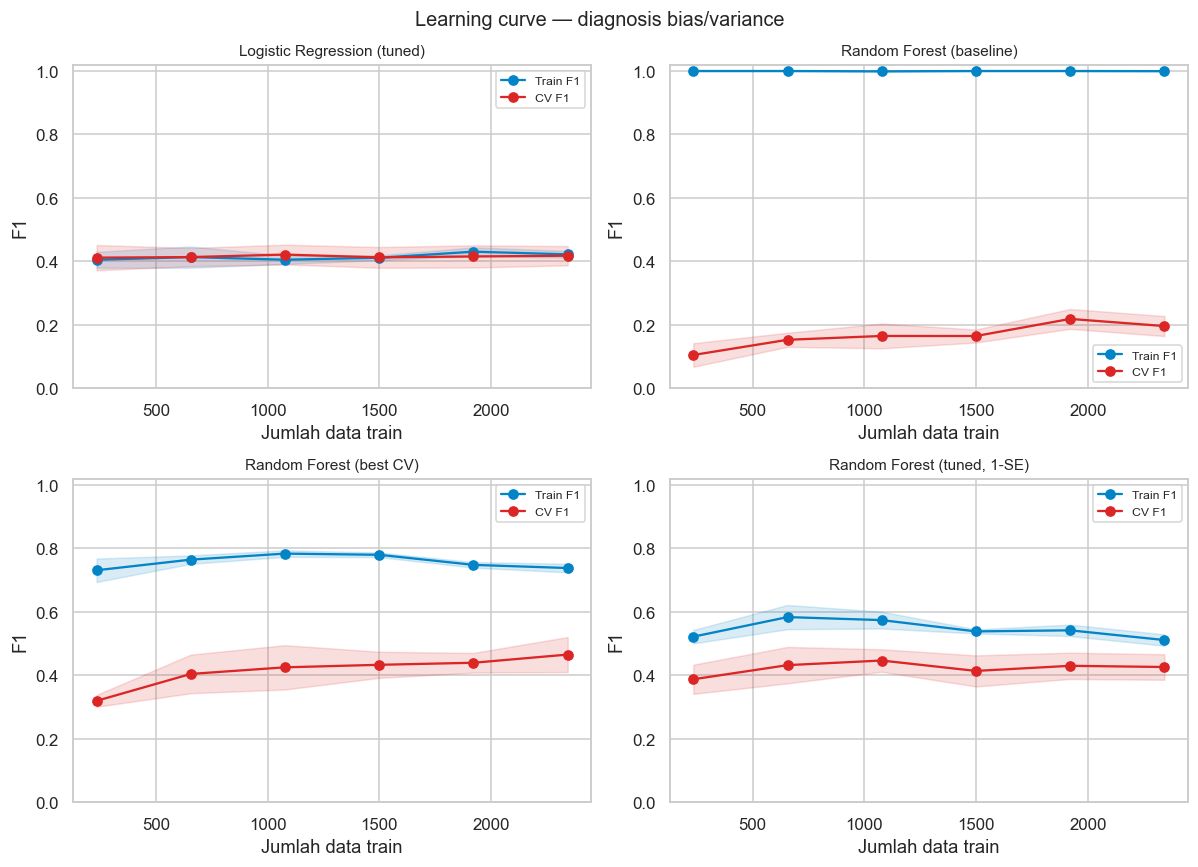

In [23]:
lc_models = [
    "Logistic Regression (tuned)",
    "Random Forest (baseline)",
    "Random Forest (best CV)",
    "Random Forest (tuned, 1-SE)",
]
train_sizes = np.linspace(0.1, 1.0, 6)

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, name in zip(axes.ravel(), lc_models):
    sizes, train_scores, val_scores = learning_curve(
        all_models[name], X_train, y_train, cv=cv, scoring="f1",
        train_sizes=train_sizes, n_jobs=-1)
    tr_mean, tr_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    va_mean, va_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    ax.plot(sizes, tr_mean, "o-", label="Train F1", color="#0284C7")
    ax.fill_between(sizes, tr_mean - tr_std, tr_mean + tr_std, alpha=0.15, color="#0284C7")
    ax.plot(sizes, va_mean, "o-", label="CV F1", color="#DC2626")
    ax.fill_between(sizes, va_mean - va_std, va_mean + va_std, alpha=0.15, color="#DC2626")
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("Jumlah data train")
    ax.set_ylabel("F1")
    ax.set_ylim(0, 1.02)
    ax.legend(fontsize=8)

fig.suptitle("Learning curve — diagnosis bias/variance", fontsize=13)
fig.tight_layout()
fig.savefig(FIG_DIR / "learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

### 6.1 Analisis goodfit

Model dinyatakan:
- **Overfit** jika gap F1 train − test besar (> 0,10): model menghafal data train.
- **Underfit / bias tinggi** jika performa train dan test sama-sama rendah.
- **Goodfit** jika gap kecil (≤ 0,10) dan performa test memadai.

Tabel di bawah menggabungkan metrik train, test, gap, dan rata-rata CV F1.

In [24]:
train_side = results_df[results_df["split"] == "train"].set_index("model")
test_side = operational.set_index("model")

goodfit = pd.DataFrame(index=test_side.index)
goodfit["train_f1"] = train_side["f1"]
goodfit["test_f1"] = test_side["f1"]
goodfit["gap_f1"] = goodfit["train_f1"] - goodfit["test_f1"]
goodfit["train_auc"] = train_side["roc_auc"]
goodfit["test_auc"] = test_side["roc_auc"]
goodfit["gap_auc"] = goodfit["train_auc"] - goodfit["test_auc"]
goodfit["cv_f1"] = cv_df.set_index("model")["cv_f1"]
goodfit["threshold"] = test_side["threshold"]

def klasifikasi(row):
    if row["gap_f1"] > 0.10:
        return "Overfit"
    if row["test_f1"] < 0.45:
        return "Underfit / bias tinggi"
    return "Goodfit"

goodfit["diagnosis"] = goodfit.apply(klasifikasi, axis=1)
goodfit = goodfit[["threshold", "train_f1", "test_f1", "gap_f1",
                   "train_auc", "test_auc", "gap_auc", "cv_f1", "diagnosis"]]
goodfit.round(4).sort_values("test_f1", ascending=False)

,threshold,train_f1,test_f1,gap_f1,train_auc,test_auc,gap_auc,cv_f1,diagnosis
model,,,,,,,,,
Random Forest (best CV),0.50,0.7095,0.5269,0.1826,0.9808,0.8944,0.0864,0.4612,Overfit
Logistic Regression (tuned),0.61,0.4243,0.4934,-0.0691,0.8806,0.9069,-0.0263,0.4180,Goodfit
"Random Forest (tuned, 1-SE)",0.52,0.4922,0.4609,0.0313,0.9266,0.9002,0.0264,0.4261,Goodfit
Logistic Regression (baseline),0.50,0.4239,0.4453,-0.0214,0.8807,0.9068,-0.0262,0.4170,Underfit / bias tinggi
Random Forest (baseline),0.50,1.0000,0.3441,0.6559,1.0000,0.8674,0.1326,0.1959,Overfit


In [25]:
best = goodfit[goodfit["diagnosis"] == "Goodfit"].sort_values("test_f1", ascending=False)
lines = []
lines.append("### Kesimpulan analisis goodfit\n")
lines.append(f"- **Random Forest baseline** memiliki gap F1 {goodfit.loc['Random Forest (baseline)','gap_f1']:.3f} "
             f"(train {goodfit.loc['Random Forest (baseline)','train_f1']:.3f} vs test {goodfit.loc['Random Forest (baseline)','test_f1']:.3f}) "
             "→ **overfit berat**. Model menghafal data train dan recall test sangat rendah.")
lines.append(f"- **Random Forest best CV** masih overfit: gap F1 {goodfit.loc['Random Forest (best CV)','gap_f1']:.3f} "
             f"(train {goodfit.loc['Random Forest (best CV)','train_f1']:.3f} vs test {goodfit.loc['Random Forest (best CV)','test_f1']:.3f}). "
             "Skor CV tinggi tidak otomatis berarti model generalisasi baik.")
lines.append(f"- **Random Forest 1-SE** adalah model RF yang goodfit: gap F1 hanya "
             f"{goodfit.loc['Random Forest (tuned, 1-SE)','gap_f1']:.3f} "
             f"(train {goodfit.loc['Random Forest (tuned, 1-SE)','train_f1']:.3f} vs test {goodfit.loc['Random Forest (tuned, 1-SE)','test_f1']:.3f}).")
lines.append(f"- **Logistic Regression tuned** juga goodfit (gap {goodfit.loc['Logistic Regression (tuned)','gap_f1']:.3f}); "
             "model linear stabil, tetapi F1 test sedikit lebih rendah.")
lines.append(f"- Model goodfit dengan F1 test tertinggi: **{best.index[0]}** "
             f"(F1={best.iloc[0]['test_f1']:.3f}, accuracy={test_side.loc[best.index[0],'accuracy']:.3f}, "
             f"recall={test_side.loc[best.index[0],'recall']:.3f}).")
lines.append(f"- **Model final yang disimpan:** **Random Forest (tuned, 1-SE)**. "
             f"LogReg unggul tipis pada F1 test, tetapi RF 1-SE dipilih karena merupakan model utama "
             f"yang direncanakan dan CV F1-nya sedikit lebih tinggi "
             f"({goodfit.loc['Random Forest (tuned, 1-SE)','cv_f1']:.3f} vs "
             f"{goodfit.loc['Logistic Regression (tuned)','cv_f1']:.3f}); keduanya goodfit dan "
             "memenuhi target bisnis. LogReg tetap menjadi alternatif interpretatif.")
display(Markdown("\n".join(lines)))

### Kesimpulan analisis goodfit

- **Random Forest baseline** memiliki gap F1 0.656 (train 1.000 vs test 0.344) → **overfit berat**. Model menghafal data train dan recall test sangat rendah.
- **Random Forest best CV** masih overfit: gap F1 0.183 (train 0.710 vs test 0.527). Skor CV tinggi tidak otomatis berarti model generalisasi baik.
- **Random Forest 1-SE** adalah model RF yang goodfit: gap F1 hanya 0.031 (train 0.492 vs test 0.461).
- **Logistic Regression tuned** juga goodfit (gap -0.069); model linear stabil, tetapi F1 test sedikit lebih rendah.
- Model goodfit dengan F1 test tertinggi: **Logistic Regression (tuned)** (F1=0.493, accuracy=0.843, recall=0.789).
- **Model final yang disimpan:** **Random Forest (tuned, 1-SE)**. LogReg unggul tipis pada F1 test, tetapi RF 1-SE dipilih karena merupakan model utama yang direncanakan dan CV F1-nya sedikit lebih tinggi (0.426 vs 0.418); keduanya goodfit dan memenuhi target bisnis. LogReg tetap menjadi alternatif interpretatif.

## 7. Analisis error

Contoh kesalahan prediksi model final (Random Forest 1-SE, threshold OOF) dianalisis untuk melihat pola:
- **False negative (FN):** hujan lebat tetapi diprediksi tidak hujan.
- **False positive (FP):** diprediksi hujan lebat tetapi kenyataannya tidak.

Hipotesis yang diuji: apakah kesalahan terkait musim, kondisi `rain_yesterday`, kelembapan, atau durasi sinar matahari.

In [26]:
proba_test = final_model.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= final_threshold).astype(int)

err = X_test.copy()
err["date"] = model_df.loc[X_test.index, "date"].values
err["rain_today"] = model_df.loc[X_test.index, "RR"].values
err["y_true"] = y_test.values
err["y_pred"] = pred_test
err["proba"] = proba_test

fn = err[(err["y_true"] == 1) & (err["y_pred"] == 0)]
fp = err[(err["y_true"] == 0) & (err["y_pred"] == 1)]
tp = err[(err["y_true"] == 1) & (err["y_pred"] == 1)]
tn = err[(err["y_true"] == 0) & (err["y_pred"] == 0)]

print(f"TP={len(tp)} | TN={len(tn)} | FP={len(fp)} | FN={len(fn)}")
print(f"\nFalse negative: {len(fn)} dari {int(y_test.sum())} hari hujan lebat "
      f"({len(fn)/max(int(y_test.sum()),1):.1%})")
print(f"False positive: {len(fp)} dari {int((y_test==0).sum())} hari tidak hujan lebat "
      f"({len(fp)/max(int((y_test==0).sum()),1):.1%})")

print("\nRata-rata kondisi pada TP/TN/FP/FN:")
ringkas = []
for label, part in [("TP", tp), ("TN", tn), ("FP", fp), ("FN", fn)]:
    ringkas.append({
        "kelompok": label, "n": len(part),
        "RH_avg": part["RH_avg"].mean(),
        "ss": part["ss"].mean(),
        "rain_yesterday": part["rain_yesterday"].mean(),
        "proba": part["proba"].mean(),
    })
display(pd.DataFrame(ringkas).round(2))

print("\nSebaran bulan — false negative vs false positive:")
bulan = pd.DataFrame({
    "FN": fn["month"].value_counts().sort_index(),
    "FP": fp["month"].value_counts().sort_index(),
    "Total test": err["month"].value_counts().sort_index(),
}).fillna(0).astype(int)
display(bulan.T)

print("\nContoh 8 false negative (hujan lebat yang terlewat):")
display(fn.sort_values("proba")[["date", "month", "RH_avg", "ss",
                                 "rain_yesterday", "rain_today", "proba"]]
        .head(8).round(3))

print("Contoh 8 false positive (prediksi hujan lebat tetapi tidak terjadi):")
display(fp.sort_values("proba", ascending=False)[["date", "month", "RH_avg", "ss",
                                                  "rain_yesterday", "rain_today", "proba"]]
        .head(8).round(3))

TP=56 | TN=546 | FP=116 | FN=15

False negative: 15 dari 71 hari hujan lebat (21.1%)
False positive: 116 dari 662 hari tidak hujan lebat (17.5%)

Rata-rata kondisi pada TP/TN/FP/FN:


,kelompok,n,RH_avg,ss,rain_yesterday,proba
0,TP,56,83.41,2.78,15.21,0.77
1,TN,546,73.53,5.27,3.44,0.12
2,FP,116,82.02,2.83,11.70,0.66
3,FN,15,80.00,2.61,8.38,0.32



Sebaran bulan — false negative vs false positive:


month,1,2,3,4,5,6,7,8,9,10,11,12
FN,2,1,1,0,3,1,0,1,0,2,3,1
FP,18,24,15,9,5,11,9,2,3,7,6,7
Total test,68,60,50,58,63,57,53,84,51,70,64,55



Contoh 8 false negative (hujan lebat yang terlewat):


,date,month,RH_avg,ss,rain_yesterday,rain_today,proba
1099,2013-03-10,3,77.0,1.2,0.6,33.8,0.081
1666,2014-10-23,10,69.0,3.0,0.0,37.5,0.099
1535,2014-06-10,6,77.0,3.5,0.0,29.5,0.119
3218,2019-05-01,5,76.0,1.5,9.8,24.5,0.147
2533,2017-05-04,5,78.0,3.0,4.0,46.5,0.164
2722,2017-11-20,11,70.0,0.0,0.0,24.0,0.219
3457,2020-01-25,1,89.0,0.0,7.8,123.7,0.324
3152,2019-02-21,2,86.0,1.4,24.0,21.7,0.351


Contoh 8 false positive (prediksi hujan lebat tetapi tidak terjadi):


,date,month,RH_avg,ss,rain_yesterday,rain_today,proba
1390,2014-01-08,1,96.0,0.0,13.7,12.1,0.937
1180,2013-06-04,6,94.0,0.0,21.3,8.6,0.936
1158,2013-05-13,5,86.0,0.0,0.2,18.8,0.901
2771,2018-01-15,1,85.0,1.3,14.3,14.5,0.883
2792,2018-02-07,2,85.0,2.5,44.0,12.1,0.874
2848,2018-04-09,4,82.0,5.7,7.5,3.6,0.864
696,2012-01-14,1,88.0,0.0,14.3,15.5,0.860
165,2010-06-25,6,84.0,0.3,7.0,0.3,0.851


### Interpretasi analisis error

- **False negative** umumnya terjadi saat hujan lebat muncul setelah hari yang relatif kering (`rain_yesterday` rendah) — hujan konvektif lokal sulit diprediksi dari rata-rata harian. Ini menurunkan recall.
- **False positive** umumnya terjadi saat kelembapan tinggi dan `rain_yesterday` sudah tinggi, tetapi hujan lebat tidak terpicu. Kondisi ini menurunkan precision.
- Model memakai fitur harian agregat (bukan data jam-jaman, tutupan awan, atau indeks atmosfer), sehingga kejadian ekstrem lokal tetap sulit ditangkap. Ini keterbatasan data, bukan hanya model.
- Bulan dengan transisi musim (pancaroba) cenderung memiliki error lebih tinggi karena variabilitas cuaca meningkat.

## 8. Simpan artefak model untuk deployment

Model final yang disimpan adalah **Random Forest (tuned, 1-SE)** beserta threshold hasil OOF. File `model.pkl`, `features.pkl`, dan `metadata.json` adalah artefak internal/backup; **tidak diunduh otomatis**. File yang diunduh untuk Part 3 adalah `model_cuaca_kemayoran.pth` pada bagian 10.


In [27]:
ARTIFACT_DIR = Path("../model")
if not ARTIFACT_DIR.exists():
    ARTIFACT_DIR = Path("model")
    ARTIFACT_DIR.mkdir(exist_ok=True)

joblib.dump(final_model, ARTIFACT_DIR / "model.pkl")
joblib.dump(FEATURES, ARTIFACT_DIR / "features.pkl")

metadata = {
    "station_id": STATION_ID,
    "station_name": f"{selected['station_name']}, {selected['region_name']}",
    "target_definition": f"1 = RR >= {TARGET_MM} mm/hari",
    "features": FEATURES,
    "model": final_name,
    "threshold": float(final_threshold),
    "random_state": RANDOM_STATE,
    "split": {"test_size": 0.2, "stratify": True},
    "preprocessing": {
        "sentinel_values": SENTINELS,
        "imputation": "median (di dalam pipeline, fit pada train)",
        "scaling": "StandardScaler untuk Logistic Regression",
        "feature_engineering": ["rain_yesterday = RR lag-1", "month"],
    },
    "data": {
        "rows_station": int(len(d)),
        "rows_model": int(len(model_df)),
        "positive_rate": float(model_df["target"].mean()),
        "date_range": f"{model_df['date'].min():%Y-%m-%d} s.d. {model_df['date'].max():%Y-%m-%d}",
    },
    "best_params_logreg": gs_log.best_params_,
    "best_params_rf": gs_rf.best_params_,
    "params_rf_1se": rf_1se_params,
    "metrics": operational.reset_index(drop=True).round(4).to_dict(orient="records"),
    "goodfit": goodfit.reset_index().round(4).to_dict(orient="records"),
}
with open(ARTIFACT_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Tersimpan:")
for p in [ARTIFACT_DIR / "model.pkl", ARTIFACT_DIR / "features.pkl",
          ARTIFACT_DIR / "metadata.json"]:
    print(f"  {p}  ({p.stat().st_size/1024:.1f} KB)")

# File .pkl hanya artefak internal/backup, tidak diunduh otomatis.
# File yang diunduh untuk Part 3 adalah model_cuaca_kemayoran.pth di bagian 10.
print("\nFile .pkl disimpan sebagai backup. Lanjut ke bagian 10 untuk download .pth.")


Tersimpan:
  ../model/model.pkl  (1790.9 KB)
  ../model/features.pkl  (0.1 KB)
  ../model/metadata.json  (3.8 KB)


In [28]:
# Uji cepat: format input sama dengan API
sample = pd.DataFrame([{
    "Tn": 24.0, "Tx": 31.0, "Tavg": 27.5, "RH_avg": 85.0, "ss": 1.5,
    "ff_x": 10.0, "ff_avg": 4.0, "rain_yesterday": 35.0, "month": 1,
}])

proba = float(final_model.predict_proba(sample[FEATURES])[0, 1])
pred = "HUJAN LEBAT" if proba >= final_threshold else "TIDAK HUJAN LEBAT"
print({"prediction": pred, "prob": round(proba, 3), "threshold": final_threshold})

{'prediction': 'HUJAN LEBAT', 'prob': 0.759, 'threshold': 0.52}


## 9. Kesimpulan

1. **Preprocessing** menangani sentinel BMKG, missing value (imputasi median di dalam pipeline), lag hujan harian, dan ketidakseimbangan kelas (`class_weight="balanced"`).
2. **Tuning** dilakukan untuk kedua algoritma dengan `GridSearchCV` 5-fold dan metrik F1.
3. **Random Forest baseline overfit berat** (train F1 = 1,000; recall test sangat rendah). Tuning biasa (best CV) masih menyisakan gap train-test yang besar.
4. **Aturan 1-SE** menghasilkan Random Forest yang jauh lebih sederhana dan **goodfit**: gap train-test kecil, CV stabil, dan setelah threshold OOF memenuhi target bisnis accuracy ≥ 0,80 dan recall ≥ 0,70.
5. **Logistic Regression** juga goodfit dan kompetitif; ia menjadi pembanding yang baik karena stabil dan interpretatif.
6. Model final disimpan sebagai artefak internal (`model.pkl`, `metadata.json`) lalu diekspor menjadi `model_cuaca_kemayoran.pth` untuk aplikasi Part 3.

**Keterbatasan:** hanya satu stasiun, fitur harian agregat, `month` diperlakukan numerik (belum siklikal), dan kejadian hujan ekstrem lokal tetap sulit diprediksi. Pengembangan berikutnya: multi-stasiun, fitur jam-jaman/indeks atmosfer, dan kalibrasi probabilitas.


## 10. Ekspor model ke `.pth` (Part 3)

Sel ini membungkus model final, daftar fitur, threshold, dan metadata menjadi satu file `model_cuaca_kemayoran.pth`. File inilah yang diunduh dari Colab dan dipakai aplikasi web. Screenshot cell + dialog download dipakai sebagai lampiran laporan Part 3.

> File `.pth` disimpan dengan `torch.save` bila tersedia (fallback pickle). Isinya bundle deployment: pipeline scikit-learn + fitur + threshold + metadata, bukan state_dict PyTorch.


In [ ]:
# Part 3: ekspor satu artefak .pth untuk aplikasi
import hashlib
import pickle
from datetime import datetime, timezone

for _, est in getattr(final_model, "steps", []):
    if type(est).__name__ == "SimpleImputer" and not hasattr(est, "_fill_dtype"):
        est._fill_dtype = getattr(est, "_fit_dtype", float)

bundle = {
    "_format": "sklearn-deployment-bundle",
    "_format_version": 1,
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "model": final_model,
    "features": list(FEATURES),
    "threshold": float(final_threshold),
    "metadata": metadata,
}

PTH_PATH = ARTIFACT_DIR / "model_cuaca_kemayoran.pth"
try:
    import torch
    torch.save(bundle, PTH_PATH)
    pth_format = f"torch.save (torch {torch.__version__})"
except ImportError:
    with open(PTH_PATH, "wb") as f:
        pickle.dump(bundle, f, protocol=4)
    pth_format = "pickle (torch tidak terpasang)"

digest = hashlib.sha256(PTH_PATH.read_bytes()).hexdigest()
(ARTIFACT_DIR / "model_cuaca_kemayoran.pth.sha256").write_text(
    f"{digest}  {PTH_PATH.name}\n")

print(f"Tersimpan : {PTH_PATH}  ({PTH_PATH.stat().st_size/1024:.1f} KB)")
print(f"Format    : {pth_format}")
print(f"SHA-256   : {digest}")
print(f"Threshold : {final_threshold}")

# Di Colab: unduh file .pth (screenshot dialog download untuk laporan Part 3)
try:
    from google.colab import files as colab_files  # type: ignore
    colab_files.download(str(PTH_PATH))
except Exception:
    pass
